# 03 — FEATURE HOG | KNN RGB224

Giữ cách viết notebook 02, dùng HOG không PCA. Đọc từng ảnh như notebook HOG cũ để tiết kiệm RAM. Chạy Run All; sửa PROJECT_ROOT nếu cần. Chỉ dùng train/dev.

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import product
import sys
import json
from skimage.feature import hog
from sklearn.preprocessing import normalize

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.value_metrics import evaluate_classification

DATA_ROOT = PROJECT_ROOT / "DATA"

## 1. Đọc dữ liệu

In [2]:
def load_image_paths_from_folder(folder):
    image_paths = []
    labels = []
    folder = Path(folder)
    class_names = sorted(
        [d.name for d in folder.iterdir() if d.is_dir() and d.name.isdigit()],
        key=int
    )
    for class_name in class_names:
        for img_path in sorted((folder / class_name).glob("*.png")):
            image_paths.append(img_path)
            labels.append(int(class_name))
    return image_paths, labels, class_names


def read_rgb224(image_path):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return cv2.resize(image, (224, 224), interpolation=cv2.INTER_LINEAR)

In [3]:
train_folder = DATA_ROOT / "train"
dev_folder = DATA_ROOT / "dev"
train_paths, train_labels, train_class_names = load_image_paths_from_folder(train_folder)
dev_paths, dev_labels, dev_class_names = load_image_paths_from_folder(dev_folder)
y_train = np.asarray(train_labels, dtype=np.int64)
y_dev = np.asarray(dev_labels, dtype=np.int64)

output_dir = PROJECT_ROOT / "src" / "KNN" / "results_224" / "hog"
output_dir.mkdir(parents=True, exist_ok=True)
print("Số ảnh train:", len(train_paths))
print("Số ảnh dev:", len(dev_paths))
print("Các lớp (VND):", train_class_names)
print("Shape ảnh mẫu:", read_rgb224(train_paths[0]).shape)

Số ảnh train: 12494
Số ảnh dev: 1564
Các lớp (VND): ['10000', '20000', '50000', '100000', '200000', '500000']
Shape ảnh mẫu: (224, 224, 3)


## 2. Trích xuất HOG

RGB224 → ảnh xám → HOG 9 hướng, cell16×16, block2×2, L2-Hys. Số chiều là 13×13×2×2×9 = 6.084. Hàm này chưa chuẩn hóa L2 toàn vector.

In [4]:
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (16, 16)
HOG_CELLS_PER_BLOCK = (2, 2)


def extract_hog(image, visualize=False):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    return hog(
        gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        transform_sqrt=False,
        visualize=visualize,
        feature_vector=True,
        channel_axis=None,
    )

In [5]:
sample_rgb = read_rgb224(train_paths[0])
sample_hog, sample_hog_image = extract_hog(sample_rgb, visualize=True)
print("Ảnh RGB mẫu:", sample_rgb.shape)
print("HOG feature shape:", sample_hog.shape)
print("L2 trước chuẩn hóa toàn vector:", np.linalg.norm(sample_hog))

Ảnh RGB mẫu: (224, 224, 3)
HOG feature shape: (6084,)
L2 trước chuẩn hóa toàn vector: 12.999999998649121


## 3. Trực quan hóa HOG

HOG mô tả đường nét trên ảnh xám, không giữ màu và không đọc chữ số như OCR. Hình dưới minh họa gradient, không phải kết quả phân loại.

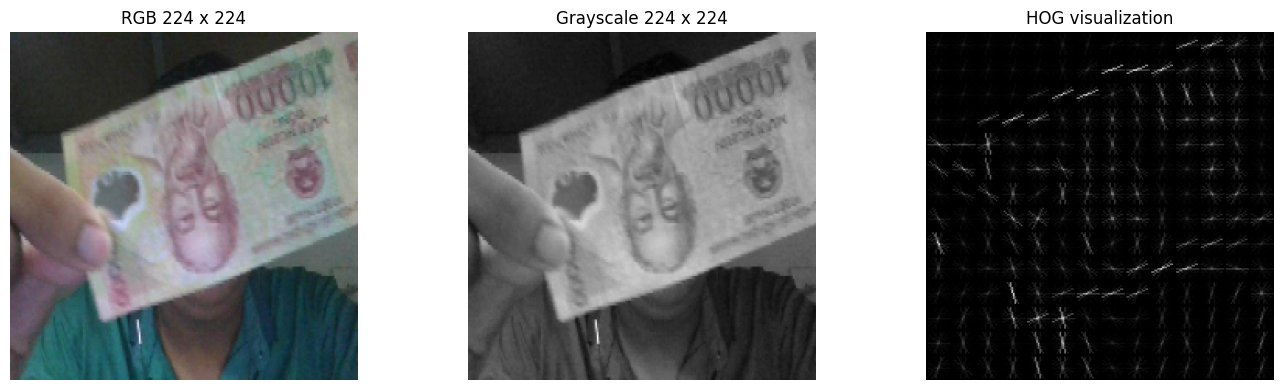

In [6]:
sample_gray = cv2.cvtColor(sample_rgb, cv2.COLOR_RGB2GRAY)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(sample_rgb)
axes[0].set_title("RGB 224 x 224")
axes[1].imshow(sample_gray, cmap="gray")
axes[1].set_title("Grayscale 224 x 224")
axes[2].imshow(sample_hog_image, cmap="gray")
axes[2].set_title("HOG visualization")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(output_dir / "hog_example.png", dpi=150)
plt.show()

In [7]:
sample_hog_normalized = normalize(sample_hog.reshape(1, -1), norm="l2")[0]
print("L2 sau chuẩn hóa toàn vector:", np.linalg.norm(sample_hog_normalized))
print("Giá trị hữu hạn:", np.isfinite(sample_hog_normalized).all())

L2 sau chuẩn hóa toàn vector: 1.0
Giá trị hữu hạn: True


Chuẩn hóa block L2-Hys và L2 toàn vector là hai bước khác nhau. Chưa kết luận hiệu quả phân loại từ một ảnh minh họa.

## 4. Trích xuất ma trận feature cho train / dev

Đọc từng ảnh, trích vector rồi bỏ ảnh khỏi RAM. Lưu bản trước L2 toàn vector cho PCA; KNN hiện tại nhận bản đã L2. Không fit PCA ở notebook này.

In [8]:
def extract_hog_from_paths(image_paths):
    features = np.empty((len(image_paths), len(sample_hog)), dtype=np.float32)
    for i, image_path in enumerate(image_paths):
        image = read_rgb224(image_path)
        features[i] = extract_hog(image)
        del image
    return features


X_train_hog_raw = extract_hog_from_paths(train_paths)
np.save(output_dir / "X_train_hog_before_l2.npy", X_train_hog_raw)
X_train_hog = normalize(X_train_hog_raw, norm="l2")
del X_train_hog_raw

X_dev_hog_raw = extract_hog_from_paths(dev_paths)
np.save(output_dir / "X_dev_hog_before_l2.npy", X_dev_hog_raw)
X_dev_hog = normalize(X_dev_hog_raw, norm="l2")
del X_dev_hog_raw

np.save(output_dir / "X_train.npy", X_train_hog)
np.save(output_dir / "X_dev.npy", X_dev_hog)
np.save(output_dir / "y_train.npy", y_train)
np.save(output_dir / "y_dev.npy", y_dev)
train_manifest = pd.DataFrame({
    "relative_path": [p.relative_to(DATA_ROOT).as_posix() for p in train_paths],
    "label_vnd": y_train,
})
dev_manifest = pd.DataFrame({
    "relative_path": [p.relative_to(DATA_ROOT).as_posix() for p in dev_paths],
    "label_vnd": y_dev,
})
train_manifest.to_csv(output_dir / "train_manifest.csv", index=False)
dev_manifest.to_csv(output_dir / "dev_manifest.csv", index=False)

print("Train:", X_train_hog.shape, y_train.shape)
print("Dev:", X_dev_hog.shape, y_dev.shape)
print("Dtype:", X_train_hog.dtype)
print("Giá trị hữu hạn:", np.isfinite(X_train_hog).all(), np.isfinite(X_dev_hog).all())
print("L2 bằng 1:",
      np.allclose(np.linalg.norm(X_train_hog, axis=1), 1.0, atol=1e-5),
      np.allclose(np.linalg.norm(X_dev_hog, axis=1), 1.0, atol=1e-5))

Train: (12494, 6084) (12494,)
Dev: (1564, 6084) (1564,)
Dtype: float32
Giá trị hữu hạn: True True
L2 bằng 1: True True


## 5. Huấn luyện KNN — Grid Search riêng cho HOG

Giữ k=1..10 × uniform/distance × Euclidean = 20 cấu hình như notebook 02. Chọn Macro-F1 cao nhất, hòa thì MAE thấp hơn, vẫn hòa thì thứ tự thử. So sánh số chưa làm tròn.

In [9]:
n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]
metric_options = ["euclidean"]

results_hog = []

for order, (k, weight, metric) in enumerate(
    product(n_neighbors_options, weight_options, metric_options)
):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric=metric,
        algorithm="brute"
    )
    knn.fit(X_train_hog, y_train)
    y_pred = knn.predict(X_dev_hog)
    scores = evaluate_classification(y_dev, y_pred)

    results_hog.append({
        "k": k,
        "weights": weight,
        "metric": metric,
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"],
        "_order": order,
    })

df_results_hog = (
    pd.DataFrame(results_hog)
    .sort_values(
        ["macro_f1", "mae_vnd", "_order"],
        ascending=[False, True, True]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

print("Tổng số cấu hình:", len(df_results_hog))
display(df_results_hog.head(10))

Tổng số cấu hình: 20


,k,weights,metric,macro_f1,mae_vnd,accuracy
0,1,uniform,euclidean,0.390748,116234.015345,0.390665
1,1,distance,euclidean,0.390748,116234.015345,0.390665
2,2,distance,euclidean,0.390748,116234.015345,0.390665
3,4,distance,euclidean,0.366091,123369.565217,0.372123
4,5,distance,euclidean,0.363930,125492.327366,0.368926
5,6,distance,euclidean,0.363796,125095.907928,0.367647
6,3,distance,euclidean,0.363499,123932.225064,0.367647
7,7,distance,euclidean,0.358674,127448.849105,0.362532
8,8,distance,euclidean,0.354998,127890.025575,0.360614
9,4,uniform,euclidean,0.348240,122583.120205,0.357417


In [10]:
# Chọn cấu hình tốt nhất và so sánh các khoảng cách
best_hog = df_results_hog.iloc[0]
print("Cấu hình HOG tốt nhất trên DEV:")
print(best_hog.to_string())

best_by_metric_hog = (
    df_results_hog
    .drop_duplicates(subset="metric", keep="first")
    .sort_values("macro_f1", ascending=False, kind="stable")
)

display(best_by_metric_hog[
    ["metric", "k", "weights", "macro_f1", "mae_vnd", "accuracy"]
])

Cấu hình HOG tốt nhất trên DEV:
k                       1
weights           uniform
metric          euclidean
macro_f1         0.390748
mae_vnd     116234.015345
accuracy         0.390665


,metric,k,weights,macro_f1,mae_vnd,accuracy
0,euclidean,1,uniform,0.390748,116234.015345,0.390665


## 6. Confusion matrix của cấu hình HOG tốt nhất trên dev

In [11]:
# Đọc trực tiếp tham số từ Grid Search (không hard-code như ví dụ RGB cũ)
best_knn_hog = KNeighborsClassifier(
    n_neighbors=int(best_hog["k"]),
    weights=str(best_hog["weights"]),
    metric=str(best_hog["metric"]),
    algorithm="brute"
)
best_knn_hog.fit(X_train_hog, y_train)
y_dev_pred_hog = best_knn_hog.predict(X_dev_hog)

hog_scores = evaluate_classification(y_dev, y_dev_pred_hog)
print("DEV Accuracy:", hog_scores["accuracy"])
print("DEV Macro-F1:", hog_scores["macro_f1"])
print("DEV MAE_VND:", hog_scores["mae_vnd"])


DEV Accuracy: 0.3906649616368286
DEV Macro-F1: 0.39074817533497597
DEV MAE_VND: 116234.01534526855


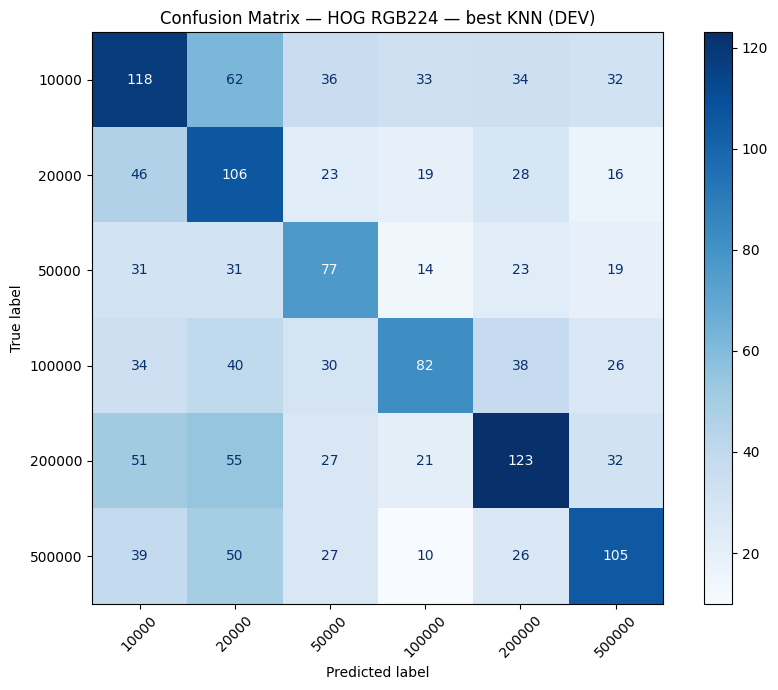

In [12]:
labels = np.sort(np.unique(y_train))
cm_hog = confusion_matrix(y_dev, y_dev_pred_hog, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_hog,
    display_labels=labels
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title("Confusion Matrix — HOG RGB224 — best KNN (DEV)")
plt.tight_layout()
plt.savefig(output_dir / "hog_confusion_matrix_dev.png", dpi=150)
plt.show()

In [13]:
# Precision / Recall / F1 theo mệnh giá — đọc được lớp nào mạnh/yếu
report_hog = classification_report(
    y_dev, y_dev_pred_hog,
    labels=labels,
    output_dict=True,
    zero_division=0
)

per_class_hog = pd.DataFrame([
    {
        "denomination_vnd": int(label),
        "precision": report_hog[str(label)]["precision"],
        "recall": report_hog[str(label)]["recall"],
        "f1": report_hog[str(label)]["f1-score"],
        "support": int(report_hog[str(label)]["support"]),
    }
    for label in labels
])
display(per_class_hog)

print(f"Số ảnh đúng: {np.trace(cm_hog)}/{cm_hog.sum()}")

,denomination_vnd,precision,recall,f1,support
0,10000,0.369906,0.374603,0.372240,315
1,20000,0.308140,0.445378,0.364261,238
2,50000,0.350000,0.394872,0.371084,195
3,100000,0.458101,0.328000,0.382284,250
4,200000,0.452206,0.398058,0.423408,309
5,500000,0.456522,0.408560,0.431211,257


Số ảnh đúng: 611/1564


In [14]:
# Những cặp mệnh giá có tổng số nhầm lẫn hai chiều lớn nhất
error_pairs_hog = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        errors_ij = int(cm_hog[i, j])
        errors_ji = int(cm_hog[j, i])
        error_pairs_hog.append({
            "pair": f"{labels[i]} ↔ {labels[j]}",
            "true_i_pred_j": errors_ij,
            "true_j_pred_i": errors_ji,
            "total_errors": errors_ij + errors_ji,
        })

df_error_pairs_hog = (
    pd.DataFrame(error_pairs_hog)
    .sort_values("total_errors", ascending=False, kind="stable")
)
print("Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:")
display(df_error_pairs_hog.head(5))

Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:


,pair,true_i_pred_j,true_j_pred_i,total_errors
0,10000 ↔ 20000,62,46,108
3,10000 ↔ 200000,34,51,85
7,20000 ↔ 200000,28,55,83
4,10000 ↔ 500000,32,39,71
1,10000 ↔ 50000,36,31,67


## Lưu kết quả để so sánh các phương án

Feature, nhãn và thứ tự ảnh đã lưu ở bước 4. File before_l2 vẫn có L2-Hys theo block, chỉ chưa L2 toàn vector. Bước PCA dùng những file này. Chạy lại cập nhật đầu ra results_224/hog; không sửa dữ liệu và không đọc test.

In [15]:
output_dir = PROJECT_ROOT / "src" / "KNN" / "results_224" / "hog"
output_dir.mkdir(parents=True, exist_ok=True)

summary_hog = pd.DataFrame([{
    "feature": "HOG RGB224 - no PCA",
    "feature_dim": X_train_hog.shape[1],
    "k": int(best_hog["k"]),
    "weights": str(best_hog["weights"]),
    "metric": str(best_hog["metric"]),
    "macro_f1": float(best_hog["macro_f1"]),
    "mae_vnd": float(best_hog["mae_vnd"]),
    "accuracy": float(best_hog["accuracy"]),
}])

df_results_hog.to_csv(output_dir / "hog_knn_grid_dev.csv", index=False)
summary_hog.to_csv(output_dir / "hog_best_dev.csv", index=False)
pd.DataFrame(cm_hog, index=labels, columns=labels).to_csv(
    output_dir / "hog_confusion_matrix_dev.csv"
)
per_class_hog.to_csv(output_dir / "hog_per_class_dev.csv", index=False)

print("Đã lưu vào:", output_dir.resolve())
display(summary_hog)

predictions = dev_manifest[["relative_path"]].copy()
predictions["y_true_vnd"] = y_dev
predictions["y_pred_vnd"] = y_dev_pred_hog
predictions.to_csv(output_dir / "predictions_dev.csv", index=False)
(output_dir / "metrics_dev.json").write_text(json.dumps(hog_scores, indent=2), encoding="utf-8")

config = {
    "image": "RGB uint8 224x224, OpenCV INTER_LINEAR",
    "orientations": HOG_ORIENTATIONS,
    "pixels_per_cell": HOG_PIXELS_PER_CELL,
    "cells_per_block": HOG_CELLS_PER_BLOCK,
    "block_norm": "L2-Hys", "transform_sqrt": False,
    "pca": False, "whole_vector_norm": "L2", "feature_dtype": "float32",
    "k_options": list(n_neighbors_options), "weight_options": weight_options,
    "metric_options": metric_options, "algorithm": "brute",
    "best_k": int(best_hog["k"]), "best_weights": str(best_hog["weights"]),
    "best_metric": str(best_hog["metric"]),
}
(output_dir / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

Đã lưu vào: C:\CS231\src\KNN\results_224\hog


,feature,feature_dim,k,weights,metric,macro_f1,mae_vnd,accuracy
0,HOG RGB224 - no PCA,6084,1,uniform,euclidean,0.390748,116234.015345,0.390665


578